## Node2Vec:

---

In [8]:
import pickle

with open('../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)

In [9]:
from node2vec import Node2Vec

node2vec = Node2Vec(
    G, 
    seed=42, 
    dimensions=64, 
    walk_length=30, 
    num_walks=200, 
    workers=4 # n_jobs
)

d:\GitHub\Repositories\Behavioral Homophily Network\behavioral-homophily-network\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Computing transition probabilities: 100%|██████████| 150/150 [00:00<00:00, 187.02it/s]


In [10]:
model = node2vec.fit(
    window=10,
    min_count=1,
    batch_words=4
)

In [11]:
embeddings = model.wv
print(f"Successfully embedded {len(embeddings.key_to_index)} nodes into 64-dimensional space.")
print("150 nodes, each represented by 64 dimensional vector")

Successfully embedded 150 nodes into 64-dimensional space.
150 nodes, each represented by 64 dimensional vector


---

## PCA:

In [12]:
print(type(embeddings))

<class 'gensim.models.keyedvectors.KeyedVectors'>


In [13]:
import numpy as np

# Converting from strings to keys
node_id = list(model.wv.key_to_index.keys())

# Sorting
node_id.sort(key=int)
vectors_64d = np.array([model.wv[str(node)] for node in node_id])

In [14]:
print(f"Class type: {type(vectors_64d)}")
print(f"Shape: {vectors_64d.shape}")


Class type: <class 'numpy.ndarray'>
Shape: (150, 64)


In [15]:
display(vectors_64d)


array([[ 0.06208999,  0.00607022,  0.1382164 , ..., -0.01431565,
         0.02314633,  0.19509831],
       [-0.05428253, -0.11729988,  0.26482996, ..., -0.09916139,
         0.18861146, -0.0789243 ],
       [ 0.16077013, -0.16227652,  0.03830081, ..., -0.05130686,
        -0.19225618,  0.10405606],
       ...,
       [ 0.03141329, -0.12203025,  0.30477574, ..., -0.04442999,
         0.3216943 , -0.13833097],
       [ 0.18142028, -0.13610423, -0.0209731 , ...,  0.04616591,
        -0.03749056,  0.20184678],
       [ 0.07846042, -0.13400735,  0.27522987, ..., -0.08402301,
         0.268595  , -0.19510806]], dtype=float32)

In [16]:
# Loading the pyshcological profile labels:

node_labels = np.load('../01-Dataset/node_labels.npy')
display(node_labels)

array([2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 1, 2,
       2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 2, 1, 0, 2, 2, 0,
       1, 0, 1, 1, 0, 2, 2, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 1, 0, 2, 1, 0,
       2, 0, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0,
       0, 2, 2, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 2, 0, 1,
       1, 1, 2, 0, 2, 1, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1], dtype=int64)

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

In [18]:
vectors_2d = pca.fit_transform(vectors_64d)
print(f"Shape: {vectors_2d.shape}")

Shape: (150, 2)


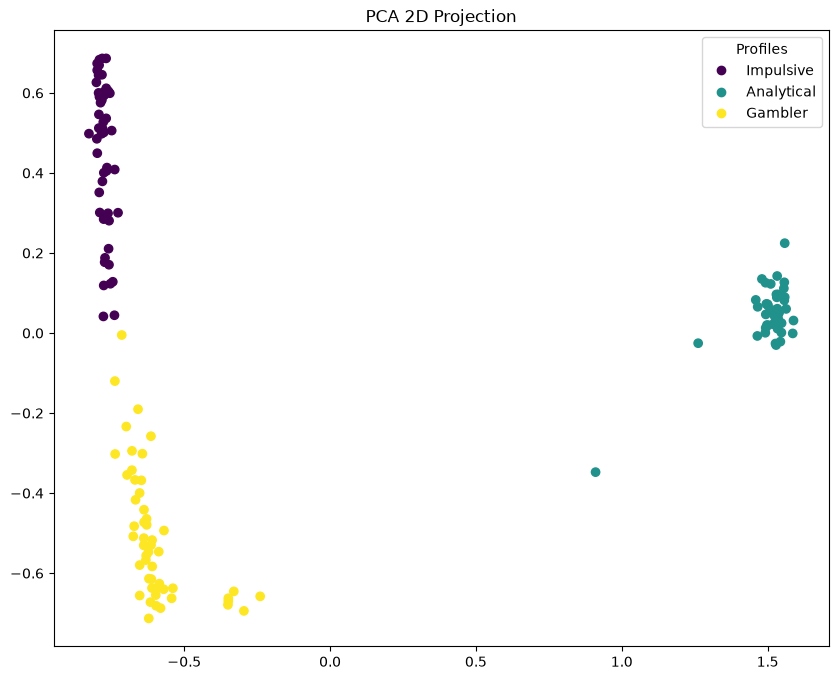

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

scatter = plt.scatter(x=vectors_2d[:, 0], y=vectors_2d[:, 1], c=node_labels)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')
plt.title('PCA 2D Projection')

plt.show()

---

### t-SNE:

In [20]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    max_iter=1000, 
    random_state=42
)

In [21]:
vectors_tsne = tsne.fit_transform(vectors_64d)